<img src="https://reqlut2.s3.amazonaws.com/uploads/alumni/0fef69ec3960b87bc64851d6ce15ebe309117cf6-javeriana.png" width="200"/>

# PONTIFICIA UNIVERSIDAD JAVERIANA
## Clase Procesamiento de datos a Gran Escala

**Fecha:** 02/10/2026  
**Autor:** Juan David Manosalva Duarte, Juan David Murcia, Sergio Clavijo, Juan Diego Soler, Isabella Achury  
**Profesor:** John Corredor  
**Tema:** Entrega 1 Proyecto

**Objetivos:**

- Aplicar la metodología CRISP DM en datasets de las ciencias de la salud
- Documentar de forma exhaustiva cada actividad realizada de la metodología
- Crear y analizar gráficas: comprender la creación de gráficas como imágenes que documenten de forma académica
- Hacer las recomendaciones, conclusiones y análisis correspondientes

In [1]:
#Generic Libraries
import findspark
findspark.init()
import numpy as np                         # linear algebra
import pandas as pd                        # data processing, CSV file I/O (e.g. pd.read_csv)
import seaborn as sns                      # Creación de gráficas y biblioteca estadística
import matplotlib.pyplot as plt            # Implementación de gráficos

#Apache Spark Libraries
import pyspark
from pyspark import SparkConf, SparkContext             # SparConf:               //SparkContext:
from pyspark.sql import SparkSession, SQLContext

#Apache Spark ML CLassifier Libraries
from pyspark.ml.classification import DecisionTreeClassifier,RandomForestClassifier,NaiveBayes

#Apache Spark Evaluation Library
from pyspark.ml.evaluation import MulticlassClassificationEvaluator

#Apache Spark Features libraries
from pyspark.ml.feature import StandardScaler,StringIndexer, VectorAssembler, VectorIndexer, OneHotEncoder

#Apache Spark Pipelin Library
from pyspark.ml import Pipeline

# Apache Spark `DenseVector`
from pyspark.ml.linalg import DenseVector  #Para poner los datos en un vector compuesto

#Data Split Libraries
import sklearn                             #Modelos de ML
from sklearn.model_selection import train_test_split

In [2]:
#Se crea una configuración para la sesión SPARK
#Se configura
configura = SparkConf()
configura.setAppName("SparkBigDataProyecto")
#Se crea el contexto para la sesión
sparkProyecto = SparkSession.builder.config(conf=configura).getOrCreate()
SQLContext(sparkContext=sparkProyecto.sparkContext, sparkSession=sparkProyecto)
#Se levanta el contexto para la sesión: Aplicación de Derrame Cerebral en SPARK
sparkContextProyecto = sparkProyecto.sparkContext.getOrCreate()
#Se imprime para verificar
print("Sesión creada el 24 sep 2026")
sparkProyecto

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


Sesión creada el 24 sep 2026


 ## Como cada miembro del cluster lo nombró distinto, lo que se hizo fue leer el de acá y pasarlo al cluster

In [3]:
import pandas as pd

archivoArrestos = pd.read_csv("NYPD_Arrest_Data_(Year_to_Date)_20261002.csv")
df00 = sparkProyecto.createDataFrame(archivoArrestos)

df00.show(5)

+----------+-----------+-----+-----------------+-----+--------------+----------+----------+-----------+---------------+-----------------+---------+--------+---------+----------+----------+---------+----------+--------------------+
|ARREST_KEY|ARREST_DATE|PD_CD|          PD_DESC|KY_CD|     OFNS_DESC|  LAW_CODE|LAW_CAT_CD|ARREST_BORO|ARREST_PRECINCT|JURISDICTION_CODE|AGE_GROUP|PERP_SEX|PERP_RACE|X_COORD_CD|Y_COORD_CD| Latitude| Longitude|            Location|
+----------+-----------+-----+-----------------+-----+--------------+----------+----------+-----------+---------------+-----------------+---------+--------+---------+----------+----------+---------+----------+--------------------+
| 318213896| 01/01/2026|105.0|STRANGULATION 1ST|106.0|FELONY ASSAULT|PL 1211200|         F|          K|             94|                0|    18-24|       M|    BLACK|    996856|    200080|40,715851|-73,954527|POINT (-73.954527...|
| 318216623| 01/01/2026|105.0|STRANGULATION 1ST|106.0|FELONY ASSAULT|PL 1211

## cantidad de individuos en la BD

In [4]:
df00.count()

26/10/02 20:52:39 WARN TaskSetManager: Stage 0 contains a task of very large size (1187 KiB). The maximum recommended task size is 1000 KiB.
                                                                                

141870

## Los disntintos tipos de datos y nombres de los parametros

In [5]:
df00.printSchema()

root
 |-- ARREST_KEY: long (nullable = true)
 |-- ARREST_DATE: string (nullable = true)
 |-- PD_CD: double (nullable = true)
 |-- PD_DESC: string (nullable = true)
 |-- KY_CD: double (nullable = true)
 |-- OFNS_DESC: string (nullable = true)
 |-- LAW_CODE: string (nullable = true)
 |-- LAW_CAT_CD: string (nullable = true)
 |-- ARREST_BORO: string (nullable = true)
 |-- ARREST_PRECINCT: long (nullable = true)
 |-- JURISDICTION_CODE: long (nullable = true)
 |-- AGE_GROUP: string (nullable = true)
 |-- PERP_SEX: string (nullable = true)
 |-- PERP_RACE: string (nullable = true)
 |-- X_COORD_CD: long (nullable = true)
 |-- Y_COORD_CD: long (nullable = true)
 |-- Latitude: string (nullable = true)
 |-- Longitude: string (nullable = true)
 |-- Location: string (nullable = true)



## agrupamos los datos por el dia en que fuero arrestados en orden ascendente

In [6]:
df00.groupBy('ARREST_DATE').count().show()


26/10/02 20:53:27 WARN TaskSetManager: Stage 3 contains a task of very large size (1706 KiB). The maximum recommended task size is 1000 KiB.
[Stage 3:>                                                          (0 + 4) / 4]

+-----------+-----+
|ARREST_DATE|count|
+-----------+-----+
| 01/12/2026|  748|
| 03/15/2026|  608|
| 06/01/2026|  791|
| 02/22/2026|  482|
| 05/25/2026|  612|
| 01/02/2026|  717|
| 04/01/2026| 1104|
| 01/15/2026|  887|
| 04/29/2026|  957|
| 05/08/2026|  913|
| 02/21/2026|  665|
| 04/08/2026|  995|
| 01/31/2026|  633|
| 04/05/2026|  529|
| 03/29/2026|  605|
| 04/18/2026|  715|
| 03/27/2026|  918|
| 06/19/2026|  634|
| 03/22/2026|  632|
| 03/11/2026| 1078|
+-----------+-----+
only showing top 20 rows


## eliminamos variables que no tengan utilidad en la investigacion

In [27]:
df01 = df00.drop("ARREST_KEY", "ARREST_DATE", "PD_CD", "KY_CD", "LAW_CODE", "JURISDICTION_CODE", "PERP_SEX", "PERP_RACE", "X_COORD_CD", "Y_COORD_CD", "PD_DESC")

## cambiamos el nombre de las variables para mayor legibilidad

In [28]:
nuevosNombres = [
    'Delito',       # Reemplaza a OFNS_DESC
    'Gravedad',     # Reemplaza a LAW_CAT_CD
    'Distrito',     # Reemplaza a ARREST_BORO
    'Precinto',     # Reemplaza a ARREST_PRECINCT
    'Edad',         # Reemplaza a AGE_GROUP
    'Latitud',      # Reemplaza a Latitude
    'Longitud',     # Reemplaza a Longitude
    'Ubicacion'     # Reemplaza a Location
]

# 3. Aplicamos el cambio de nombre
df02 = df01
for antes, nuevo in zip(df01.columns, nuevosNombres):
    df02 = df02.withColumnRenamed(antes, nuevo)

# 4. Comprobamos la estructura y los primeros datos
df02.printSchema()


root
 |-- Delito: string (nullable = true)
 |-- Gravedad: string (nullable = true)
 |-- Distrito: string (nullable = true)
 |-- Precinto: long (nullable = true)
 |-- Edad: string (nullable = true)
 |-- Latitud: string (nullable = true)
 |-- Longitud: string (nullable = true)
 |-- Ubicacion: string (nullable = true)

+--------------+--------+--------+--------+-----+---------+----------+--------------------+
|        Delito|Gravedad|Distrito|Precinto| Edad|  Latitud|  Longitud|           Ubicacion|
+--------------+--------+--------+--------+-----+---------+----------+--------------------+
|FELONY ASSAULT|       F|       K|      94|18-24|40,715851|-73,954527|POINT (-73.954527...|
|FELONY ASSAULT|       F|       M|      24|45-64|40,801304|-73,968816|POINT (-73.968816...|
|FELONY ASSAULT|       F|       K|      61|45-64|40,597437|-73,949512|POINT (-73.949512...|
|FELONY ASSAULT|       F|       Q|     116|25-44|40,666435|-73,784559|POINT (-73.784559...|
|FELONY ASSAULT|       F|       K|    

In [29]:
df02.show()

+--------------------+--------+--------+--------+-----+-----------+------------+--------------------+
|              Delito|Gravedad|Distrito|Precinto| Edad|    Latitud|    Longitud|           Ubicacion|
+--------------------+--------+--------+--------+-----+-----------+------------+--------------------+
|      FELONY ASSAULT|       F|       K|      94|18-24|  40,715851|  -73,954527|POINT (-73.954527...|
|      FELONY ASSAULT|       F|       M|      24|45-64|  40,801304|  -73,968816|POINT (-73.968816...|
|      FELONY ASSAULT|       F|       K|      61|45-64|  40,597437|  -73,949512|POINT (-73.949512...|
|      FELONY ASSAULT|       F|       Q|     116|25-44|  40,666435|  -73,784559|POINT (-73.784559...|
|      FELONY ASSAULT|       F|       K|      73|25-44|  40,671112|  -73,913564|POINT (-73.913564...|
|      FELONY ASSAULT|       F|       Q|     116|18-24|  40,654444|  -73,735523|POINT (-73.735523...|
|     DANGEROUS DRUGS|       F|       M|      14|18-24|   40,75253|  -73,993223|PO

## muestra los datos con los que trabajaremos

In [30]:
df02.printSchema()

root
 |-- Delito: string (nullable = true)
 |-- Gravedad: string (nullable = true)
 |-- Distrito: string (nullable = true)
 |-- Precinto: long (nullable = true)
 |-- Edad: string (nullable = true)
 |-- Latitud: string (nullable = true)
 |-- Longitud: string (nullable = true)
 |-- Ubicacion: string (nullable = true)



In [16]:
 !pip install matplotlib

In [31]:
df02.describe().show()

26/10/02 21:30:43 WARN TaskSetManager: Stage 9 contains a task of very large size (13829 KiB). The maximum recommended task size is 1000 KiB.
[Stage 11:>                                                         (0 + 1) / 1]

+-------+--------------------+--------+--------+-----------------+------+---------+----------+--------------------+
|summary|              Delito|Gravedad|Distrito|         Precinto|  Edad|  Latitud|  Longitud|           Ubicacion|
+-------+--------------------+--------+--------+-----------------+------+---------+----------+--------------------+
|  count|              141870|  141006|  141870|           141870|141870|   141870|    141870|              141870|
|   mean|                NULL|     9.0|    NULL|63.41103827447663|  NULL|     NULL|      NULL|                NULL|
| stddev|                NULL|     0.0|    NULL|34.00822228324091|  NULL|     NULL|      NULL|                NULL|
|    min|              (null)|  (null)|       B|                1| 18-24|  40,5011|-73,700287|POINT (-73.700287...|
|    max|VEHICLE AND TRAFF...|       V|       S|              123|   <18|40,911307|-74,253049|POINT (-74.253049...|
+-------+--------------------+--------+--------+-----------------+------

## cambiamos el tipo de dato de variables (casteo)

In [32]:
### Delito: se castea a texto (string es el equivalente a char en PySpark)
df03 = df02.withColumn("Delito", df02.Delito.cast("string"))

### Gravedad: se castea a texto (string)
df03 = df03.withColumn("Gravedad", df03.Gravedad.cast("string"))

### Distrito: se castea a entero (int)
df03 = df03.withColumn("Distrito", df03.Distrito.cast("int"))

## graficas

26/10/02 21:36:11 WARN TaskSetManager: Stage 15 contains a task of very large size (1429 KiB). The maximum recommended task size is 1000 KiB.


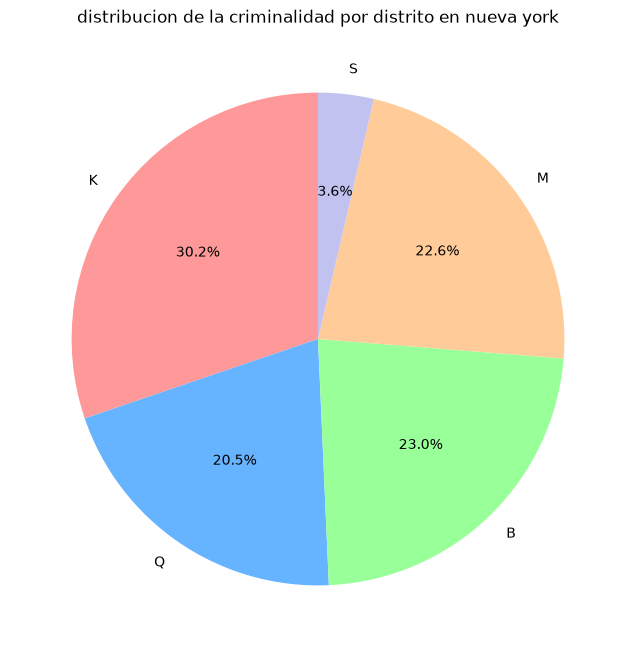

In [34]:
import matplotlib.pyplot as plt


delitos_por_distrito = df02.groupBy("Distrito").count()


pd_distrito = delitos_por_distrito.toPandas()


plt.figure(figsize=(8, 8)) 
plt.pie(
    pd_distrito['count'],              
    labels=pd_distrito['Distrito'],   
    autopct='%1.1f%%',              
    startangle=90,               
    colors=['#ff9999','#66b3ff','#99ff99','#ffcc99', '#c2c2f0'] 
)


plt.title('distribucion de la criminalidad por distrito en nueva york')
plt.show()

26/10/02 21:42:52 WARN TaskSetManager: Stage 18 contains a task of very large size (1429 KiB). The maximum recommended task size is 1000 KiB.


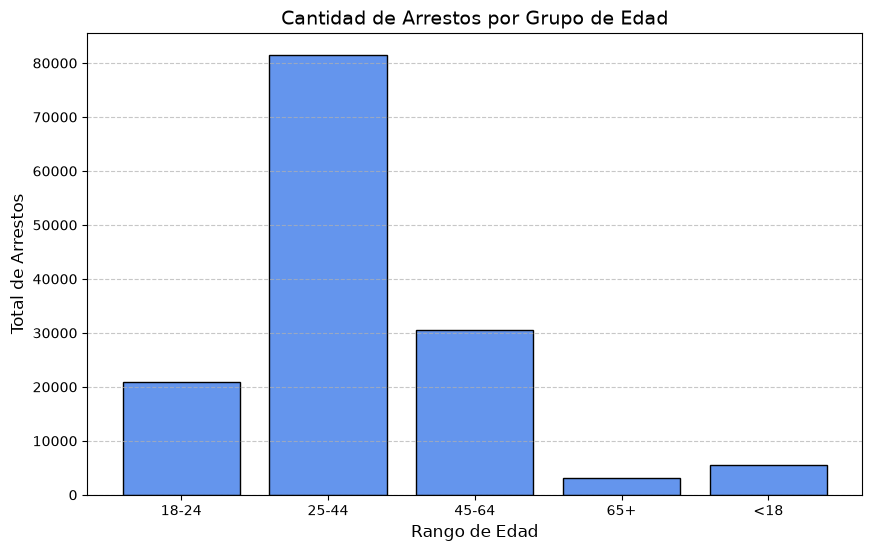

In [35]:
import matplotlib.pyplot as plt

edades_spark = df02.groupBy("Edad").count()

pd_edades = edades_spark.toPandas()

pd_edades = pd_edades.sort_values(by='Edad')

plt.figure(figsize=(10, 6))

plt.bar(pd_edades['Edad'], pd_edades['count'], color='cornflowerblue', edgecolor='black')

plt.title('Cantidad de Arrestos por Grupo de Edad', fontsize=14)
plt.xlabel('Rango de Edad', fontsize=12)
plt.ylabel('Total de Arrestos', fontsize=12)

plt.xticks(rotation=0) 

plt.grid(axis='y', linestyle='--', alpha=0.7)

plt.show()

26/10/02 21:48:42 WARN TaskSetManager: Stage 21 contains a task of very large size (1930 KiB). The maximum recommended task size is 1000 KiB.


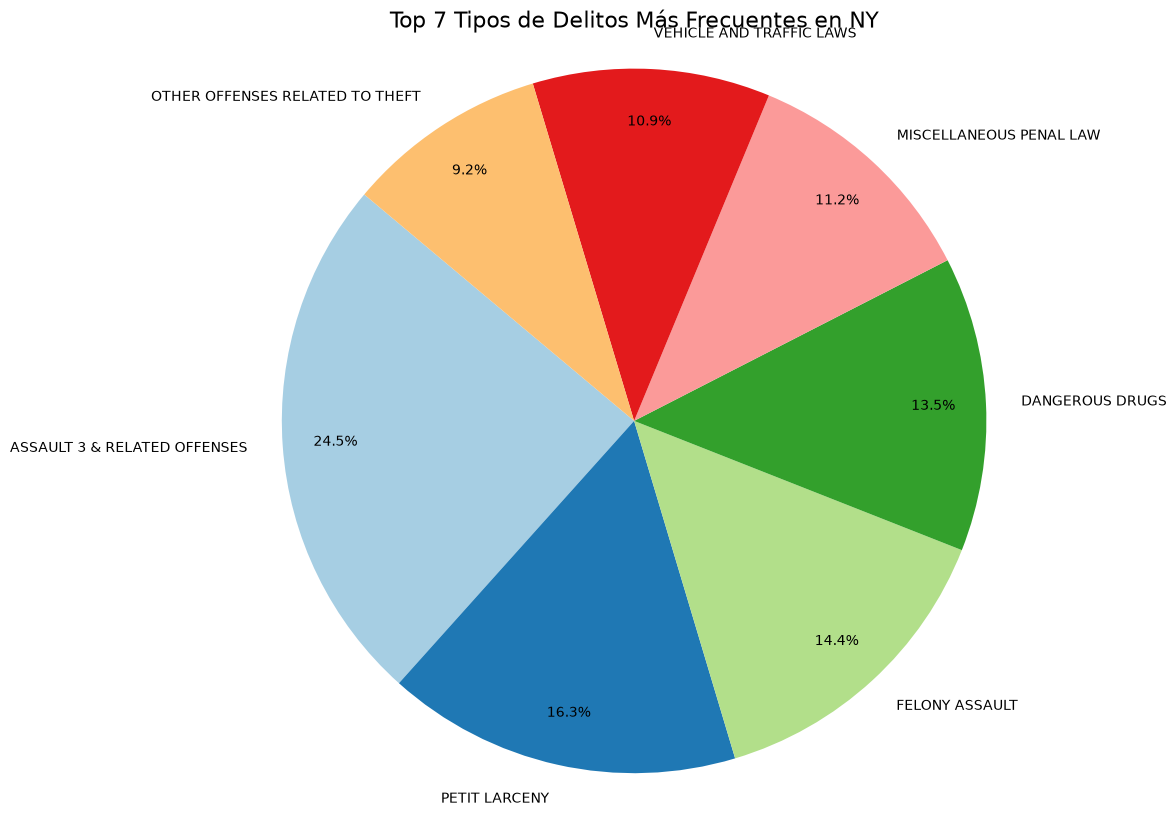

In [36]:
import matplotlib.pyplot as plt

delitos_spark = df02.groupBy("Delito").count().orderBy("count", ascending=False)

pd_delitos = delitos_spark.toPandas()

top_delitos = pd_delitos.head(7)


plt.figure(figsize=(11, 11))

plt.pie(
    top_delitos['count'], 
    labels=top_delitos['Delito'], 
    autopct='%1.1f%%', 
    startangle=140,

    pctdistance=0.85,
    colors=plt.cm.Paired.colors 
)

plt.title('Top 7 Tipos de Delitos Más Frecuentes en NY', fontsize=16)

plt.axis('equal') 

plt.show()

26/10/02 21:52:52 WARN TaskSetManager: Stage 43 contains a task of very large size (1983 KiB). The maximum recommended task size is 1000 KiB.
26/10/02 21:52:58 WARN TaskSetManager: Stage 51 contains a task of very large size (1983 KiB). The maximum recommended task size is 1000 KiB.


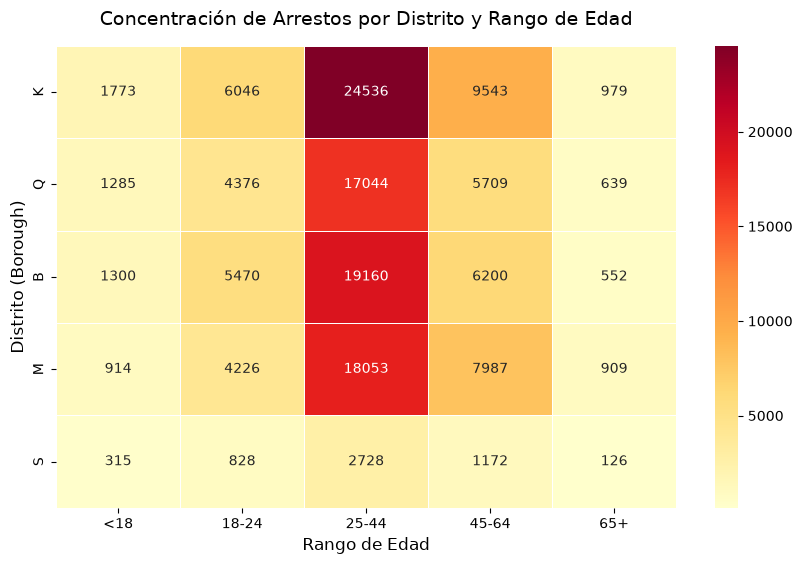

In [38]:
import matplotlib.pyplot as plt
import seaborn as sns

tabla_cruzada = df02.stat.crosstab("Distrito", "Edad")

pd_heatmap = tabla_cruzada.toPandas()

pd_heatmap = pd_heatmap.set_index('Distrito_Edad')

columnas_ordenadas = ['<18', '18-24', '25-44', '45-64', '65+']
columnas_presentes = [col for col in columnas_ordenadas if col in pd_heatmap.columns]
pd_heatmap = pd_heatmap[columnas_presentes]

plt.figure(figsize=(10, 6))

sns.heatmap(pd_heatmap, annot=True, fmt='d', cmap='YlOrRd', linewidths=.5)

plt.title('Concentracion de Arrestos por Distrito y Rango de Edad', fontsize=14, pad=15)
plt.xlabel('Rango de Edad', fontsize=12)
plt.ylabel('Distrito (Borough)', fontsize=12)

plt.show()

In [39]:
import os
from itertools import chain
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pyspark.sql import functions as F

CARPETA_SALIDA = "punto7_salida"         
os.makedirs(CARPETA_SALIDA, exist_ok=True)

BASE_POBLACION = "censo_2020"            
POBLACION = {
    "censo_2020":    {"Bronx": 1472654, "Brooklyn": 2736074, "Manhattan": 1694251, "Queens": 2405464, "Staten Island": 495747},
    "estimada_2025": {"Bronx": 1406332, "Brooklyn": 2653963, "Manhattan": 1664862, "Queens": 2358182, "Staten Island": 501290},
}
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

In [40]:
print("Columnas de df02:", df02.columns)
n0 = df02.count()
repetidas = n0 - df02.dropDuplicates().count()
print(f"Filas: {n0:,}")
print(f"Filas idénticas en las 8 columnas: {repetidas:,} ({repetidas / n0 * 100:.1f}% del total)")

Columnas de df02: ['Delito', 'Gravedad', 'Distrito', 'Precinto', 'Edad', 'Latitud', 'Longitud', 'Ubicacion']


26/10/02 22:24:54 WARN TaskSetManager: Stage 60 contains a task of very large size (6920 KiB). The maximum recommended task size is 1000 KiB.
[Stage 62:>                                                         (0 + 4) / 4]

Filas: 141,870
Filas idénticas en las 8 columnas: 64,774 (45.7% del total)


In [42]:
CENTINELAS = ["(NULL)", "NULL", "NAN", "NONE", ""]

def resumen_faltantes(df):
    """Por columna: vacíos reales y textos 'sin dato'. Solo muestra las columnas que tienen algo."""
    exprs = []
    for c, t in df.dtypes:
        exprs.append(F.sum(F.col(c).isNull().cast("int")).alias(f"{c}|nulos"))
        if t == "string":
            exprs.append(F.sum(F.upper(F.trim(F.col(c))).isin(CENTINELAS).cast("int")).alias(f"{c}|textos_sin_dato"))
    fila = df.agg(*exprs).first().asDict()
    tabla = {}
    for k, v in fila.items():
        col, tipo = k.split("|")
        tabla.setdefault(col, {"nulos": 0, "textos_sin_dato": 0})[tipo] = int(v or 0)
    out = pd.DataFrame(tabla).T
    out["total"] = out.sum(axis=1)
    return out[out["total"] > 0].sort_values("total", ascending=False)

bitacora = []
def registrar(paso, antes, despues, afectadas=None):
    afectadas = (antes - despues) if afectadas is None else afectadas
    bitacora.append({"paso": paso, "filas_antes": antes, "filas_despues": despues, "afectadas": afectadas})
    print(f"{paso}\n   antes: {antes:,} | después: {despues:,} | afectadas: {afectadas:,}")

print("Faltantes en df02:")
resumen_faltantes(df02)

Faltantes en df02:


26/10/02 22:25:52 WARN TaskSetManager: Stage 69 contains a task of very large size (6920 KiB). The maximum recommended task size is 1000 KiB.
                                                                                

,nulos,textos_sin_dato,total
Gravedad,864,5,869
Delito,0,24,24


In [43]:
def texto_a_nulo(df):
    """En las columnas de texto, '(null)', 'nan' y las cadenas vacías pasan a vacío real; se recortan los espacios."""
    for c, t in df.dtypes:
        if t == "string":
            limpio = F.trim(F.col(c))
            df = df.withColumn(c, F.when(F.upper(limpio).isin(*CENTINELAS), F.lit(None).cast("string")).otherwise(limpio))
    return df

def a_decimal(c):
    t = F.regexp_replace(F.trim(F.col(c)), ",", ".")
    return F.when(t.rlike(r"^-?[0-9]+(\.[0-9]+)?$"), t.cast("double"))

base = texto_a_nulo(df02)
df05, filas = base, []
for c in ["Latitud", "Longitud"]:
    antes = df05.filter(F.col(c).isNull()).count()
    df05 = df05.withColumn(c, a_decimal(c))
    despues = df05.filter(F.col(c).isNull()).count()
    filas.append({"columna": c, "nulos_antes": antes, "nulos_despues": despues, "nuevos": despues - antes, "ALERTA": despues > antes})
print(pd.DataFrame(filas).to_string(index=False))
df05 = df05.cache()
df05.printSchema()
df05.select("Delito", "Gravedad", "Distrito", "Precinto", "Edad", "Latitud", "Longitud").show(5)
df05.select(F.min("Latitud"), F.max("Latitud"), F.min("Longitud"), F.max("Longitud"), F.min("Precinto"), F.max("Precinto")).show()
print("Faltantes después del tipado:")
resumen_faltantes(df05)

 columna  nulos_antes  nulos_despues  nuevos  ALERTA
 Latitud            0              0       0   False
Longitud            0              0       0   False
root
 |-- Delito: string (nullable = true)
 |-- Gravedad: string (nullable = true)
 |-- Distrito: string (nullable = true)
 |-- Precinto: long (nullable = true)
 |-- Edad: string (nullable = true)
 |-- Latitud: double (nullable = true)
 |-- Longitud: double (nullable = true)
 |-- Ubicacion: string (nullable = true)



26/10/02 22:29:55 WARN TaskSetManager: Stage 80 contains a task of very large size (5828 KiB). The maximum recommended task size is 1000 KiB.
                                                                                

+--------------+--------+--------+--------+-----+---------+----------+
|        Delito|Gravedad|Distrito|Precinto| Edad|  Latitud|  Longitud|
+--------------+--------+--------+--------+-----+---------+----------+
|FELONY ASSAULT|       F|       K|      94|18-24|40.715851|-73.954527|
|FELONY ASSAULT|       F|       M|      24|45-64|40.801304|-73.968816|
|FELONY ASSAULT|       F|       K|      61|45-64|40.597437|-73.949512|
|FELONY ASSAULT|       F|       Q|     116|25-44|40.666435|-73.784559|
|FELONY ASSAULT|       F|       K|      73|25-44|40.671112|-73.913564|
+--------------+--------+--------+--------+-----+---------+----------+
only showing top 5 rows


26/10/02 22:29:58 WARN TaskSetManager: Stage 81 contains a task of very large size (5828 KiB). The maximum recommended task size is 1000 KiB.
26/10/02 22:30:01 WARN TaskSetManager: Stage 82 contains a task of very large size (5828 KiB). The maximum recommended task size is 1000 KiB.
                                                                                

+------------+------------+-------------+-------------+-------------+-------------+
|min(Latitud)|max(Latitud)|min(Longitud)|max(Longitud)|min(Precinto)|max(Precinto)|
+------------+------------+-------------+-------------+-------------+-------------+
|     40.5011|   40.911307|   -74.253049|   -73.700287|            1|          123|
+------------+------------+-------------+-------------+-------------+-------------+

Faltantes después del tipado:


26/10/02 22:30:07 WARN TaskSetManager: Stage 85 contains a task of very large size (5828 KiB). The maximum recommended task size is 1000 KiB.
                                                                                

,nulos,textos_sin_dato,total
Gravedad,869,0,869
Delito,24,0,24
